In [3]:
import torch
import itertools
import numpy as np

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Circle
from matplotlib.ticker import MaxNLocator
import matplotlib.patheffects as pe


# Task1: Energy functions

## DW-4
- Shape: (4x2) Four Particles in 2D  $x \in \mathcal{R}^8$
- Energy: $$E(x) = \frac{1}{2\tau}\sum_{i \neq j} \Big[\, a\,(d_{ij}-d_0) + b\,(d_{ij}-d_0)^2 + c\,(d_{ij}-d_0)^4 \Big], \qquad d_{ij} = \lVert x_i - x_j \rVert_2$$

In [109]:
# DEFAULT PARAMETERS
A = 0
B = -4
C = 0.9
D_0 = 4
R_SHORT = D_0 - np.sqrt(-B / (2 * C))
R_LONG = D_0 + np.sqrt(-B / (2 * C))

def DW_energy(x, temp=1):
    "Make sure the shape is batched: (Bx4x2)"
    print(x.shape)
    d = torch.cdist(x, x)
    i, j = torch.triu_indices(4, 4, offset=1)
    return DW_pair_potential(d[:, i, j]).sum(-1) / temp

def DW_pair_potential(s, a=A, b=B, c=C, d_0=D_0):
    s = s - d_0
    return a * s + b * s**2 + c * s**4


In [110]:
# Examples Generated by Claude
_MINIMA = {
    # two short bonds from particle 0; particle 3 sits in the long well of all others
    "kite (global min)":   [[-1.6379, 0.0], [-1.0725, -2.6391], [-1.0725, 2.6391], [3.7830, 0.0]],
    # triangle 1-2-3 of short bonds plus a "tail" particle 0
    "triangle + tail":     [[-3.3160, 0.0], [-0.4669, 0.0], [1.8914, 1.2385], [1.8914, -1.2385]],
    "rectangle":           [[-2.5808, -1.2062], [-2.5808, 1.2062], [2.5808, 1.2062], [2.5808, -1.2062]],
    "rhombus":             [[-2.4297, 0.0], [0.0, 1.1923], [0.0, -1.1923], [2.4297, 0.0]],
    # particle 1 at the center of an equilateral triangle
    "centered triangle":   [[-2.8775, 1.0207], [0.0, 0.0], [0.5548, -3.0024], [2.3227, 1.9816]],
}
_s = 2.51 / 2
_HAND_BUILT = {
    # every side at the short minimum, but diagonals (3.55) are frustrated
    "square, side 2.51":   [[-_s, -_s], [-_s, _s], [_s, _s], [_s, -_s]],
    # every side exactly on the barrier top r = d0
    "square, side 4":      [[-2.0, -2.0], [-2.0, 2.0], [2.0, 2.0], [2.0, -2.0]],
    # pair 0-3 at r = 7.5 sits high on the quartic wall
    "line, spacing 2.5":   [[-3.75, 0.0], [-1.25, 0.0], [1.25, 0.0], [3.75, 0.0]],
    # all particles on top of each other: finite energy, v(0) = 166.4 per pair
    "collapsed":           [[0.0, 0.0]] * 4,
}
# Reference energies (tau = 1, sum over the 6 unique pairs)
_E_REF = {
    "kite (global min)": -25.7922, "triangle + tail": -25.3124, "rectangle": -24.3524,
    "rhombus": -23.4654, "centered triangle": -21.0665, "square, side 2.51": -19.3261,
    "square, side 4": -8.3966, "line, spacing 2.5": 66.5250, "collapsed": 998.4000,
}
chosen = _MINIMA
names = list(chosen)
X = torch.tensor([chosen[n] for n in names]).reshape(-1,4,2)
E = torch.tensor([_E_REF[n] for n in names]).reshape(-1,)
samples = dict(zip(names, X))
X.shape, E.shape

(torch.Size([5, 4, 2]), torch.Size([5]))

# Task 2: Visualization of configurations and their energies
- Pair potential as a function of the distance visualization
- 1D Slices

In [146]:
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MOVE_COLOR = SERIES[2] 
PAIRS = list(itertools.combinations(range(4), 2))
def plot_pair_potential(pair_potential_func, ax=None, r_max=8.0, ylim=(-6, 20)):
    ax = ax or plt.gca()
    r = np.linspace(0, r_max, 800)
    ax.plot(r, pair_potential_func(r), color=SERIES[0])
    v_min = pair_potential_func(R_SHORT)
    for rr, txt in [(R_SHORT, f"min r={R_SHORT:.2f}"), (D_0, f"barrier r={D_0:.0f}"),
                    (R_LONG, f"min r={R_LONG:.2f}")]:
        ax.axvline(rr, color=MUTED, lw=0.8, ls="--", zorder=0)
        ax.annotate(txt, (rr, ylim[1]), xytext=(3, -4), textcoords="offset points", ha="left", va="top", fontsize=8, color=INK2)
    ax.axhline(0, color=AXIS, lw=0.8, zorder=0)
    ax.set(xlim=(0, r_max), ylim=ylim, xlabel="pair distance r", ylabel="v(r)", title="Pair potential")
    return ax


<Axes: title={'center': 'Pair potential'}, xlabel='pair distance r', ylabel='v(r)'>

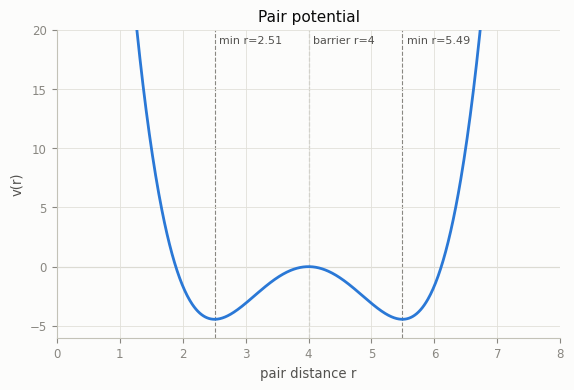

In [147]:
fig, ax = plt.subplots(figsize=(6.5, 4))
plot_pair_potential(DW_pair_potential, ax)

In [148]:
def slice_1d(energy_fn, x0, k, vec, ts):
    """E(x0 + t * d), where d moves only particle k along vec. Returns a numpy array (len(ts),)."""
    x0 = np.asarray(x0, dtype=float).ravel()
    d = np.zeros((4, 2))
    d[k] = vec
    moved = torch.tensor(x0[None] + np.asarray(ts)[:, None] * d.ravel()[None]).view(-1, 4, 2)
    with torch.no_grad():
        E = energy_fn(moved)
    return E.detach().cpu().numpy().reshape(-1)
 
 
def move_particle(x0, k, vec, t):
    """Copy of x0 (as (4, 2)) with particle k shifted by t * vec."""
    p = np.asarray(x0, dtype=float).reshape(4, 2).copy()
    p[k] += t * np.asarray(vec, dtype=float)
    return p
 
 
def plot_configuration(x, ax=None, lim=5.0, center=None, highlight=None, ghost=None, title=None):
    """Particles with pair bonds: solid = short well (r<d0), dashed = long well (r>d0),
    dotted gray = on the barrier (|r - d0| < 0.05).
    center:    point subtracted from all positions (default: this configuration's mean).
               Pass the same center for before/after panels so they share a frame.
    highlight: index of a particle to ring in MOVE_COLOR.
    ghost:     earlier position of the highlighted particle, drawn hollow with an arrow."""
    ax = ax or plt.gca()
    p = np.asarray(x, dtype=float).reshape(4, 2)
    c = p.mean(0) if center is None else np.asarray(center, dtype=float)
    p = p - c
    for i, j in PAIRS:
        r = np.linalg.norm(p[i] - p[j])
        if abs(r - D_0) < 0.05:
            style = dict(color=MUTED, ls=":", lw=1.4)
        elif r < D_0:
            style = dict(color=SERIES[0], ls="-", lw=1.6)
        else:
            style = dict(color=SERIES[1], ls=(0, (3, 2)), lw=1.0)
        ax.plot(*p[[i, j]].T, zorder=1, **style)
    if ghost is not None and highlight is not None:
        g = np.asarray(ghost, dtype=float) - c
        ax.scatter(*g, s=110, facecolor="none", edgecolor=MUTED, linewidth=1.4, ls="--", zorder=2)
        ax.annotate("", xy=p[highlight], xytext=g, zorder=2,
                    arrowprops=dict(arrowstyle="->", color=MOVE_COLOR, lw=1.4,
                                    shrinkA=7, shrinkB=7))
    ax.scatter(*p.T, s=110, color=INK, edgecolor=SURFACE, linewidth=2, zorder=3)
    if highlight is not None:
        ax.scatter(*p[highlight], s=260, facecolor="none", edgecolor=MOVE_COLOR, linewidth=2,
                   zorder=3)
    for k, (px, py) in enumerate(p):
        ax.annotate(str(k), (px, py), ha="center", va="center", color="white",
                    fontsize=7, fontweight="bold", zorder=4)
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect="equal", xticks=[], yticks=[])
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    if title is not None:
        ax.set_title(title, fontsize=10)
    return ax
 
 
def plot_particle_slice_1d(energy_fn, x0, k, pair_potential=DW_pair_potential, vec=(1.0, 0.0),
                           t_range=(-4, 4), n=400, show_pairs=True, ax=None, ylim=None,
                           t_post=None):
    """Move particle k along `vec`, others fixed. Optionally overlay the 3 pair terms involving k
    (from the reference pair potential; distinct dash styles so coinciding terms stay visible).
    t_post: if given, mark the displacement shown in the "after" panel."""
    ax = ax or plt.gca()
    vec = np.asarray(vec, float) / np.linalg.norm(vec)
    ts = np.linspace(*t_range, n)
    E = slice_1d(energy_fn, x0, k, vec, ts)
    ax.plot(ts, E, color=INK, lw=2.2, label="total E", zorder=3)
    if show_pairs:
        p = np.asarray(x0, dtype=float).reshape(4, 2)
        others = [j for j in range(4) if j != k]
        for c, ls, j in zip(SERIES, ["-", (0, (5, 2)), (0, (1.5, 1.5))], others):
            r = np.linalg.norm(p[k][None] + ts[:, None] * vec[None] - p[j][None], axis=-1)
            ax.plot(ts, pair_potential(r), color=c, ls=ls, lw=1.6,
                    label=rf"$v(r_{{{k}{j}}})$")
    ax.axvline(0, color=MUTED, lw=0.8, ls="--", zorder=0)
    side = 1 if (t_post is None or t_post <= 0) else -1      # keep the two labels apart
    ax.annotate("before", (0, 1), xycoords=("data", "axes fraction"), xytext=(3 * side, -3),
                textcoords="offset points", ha="left" if side > 0 else "right", va="top",
                fontsize=8, color=INK2)
    if t_post is not None:
        e_post = slice_1d(energy_fn, x0, k, vec, [t_post])[0]
        ax.axvline(t_post, color=MOVE_COLOR, lw=1.0, ls="--", zorder=0)
        ax.scatter([t_post], [e_post], s=45, color=MOVE_COLOR, edgecolor=SURFACE, linewidth=1.5,
                   zorder=4)
        ax.annotate("after", (t_post, 1), xycoords=("data", "axes fraction"),
                    xytext=(-3 * side, -3), textcoords="offset points",
                    ha="right" if side > 0 else "left", va="top", fontsize=8, color=INK2)
    ax.set(xlabel=f"displacement of particle {k} along ({vec[0]:.2f}, {vec[1]:.2f})",
           ylabel="energy")
    if ylim is None:
        lo = min(E.min(), -5)
        ylim = (lo - 2, E.min() + 40)
    ax.set_ylim(ylim)
    ax.legend(loc="lower left", frameon=True, facecolor=SURFACE, edgecolor="none", framealpha=0.9)
    return ax


def plot_move(energy_fn, x0, k, vec=(1.0, 0.0), t_range=(-4, 4), t_post=None, min_shift=0.5, axes=None, pair_potential=DW_pair_potential, n=400, lim=None, **slice_kwargs):
    if axes is None:
        _, axes = plt.subplots(1, 3, figsize=(14, 4.6), layout="constrained",
                               gridspec_kw={"width_ratios": [1, 1.6, 1]})
    vec = np.asarray(vec, float) / np.linalg.norm(vec)
    if t_post is None:
        ts = np.linspace(*t_range, n)
        E = slice_1d(energy_fn, x0, k, vec, ts)
        is_min = np.r_[False, (E[1:-1] < E[:-2]) & (E[1:-1] <= E[2:]), False]
        cand = np.where(is_min & (np.abs(ts) >= min_shift))[0]
        if len(cand):
            t_post = ts[cand[np.argmin(E[cand])]]
        else:
            t_post = ts[0] if E[0] < E[-1] else ts[-1]
 
    pre = np.asarray(x0, dtype=float).reshape(4, 2)
    post = move_particle(pre, k, vec, t_post)
    e_pre, e_post = slice_1d(energy_fn, pre, k, vec, [0.0, t_post])
    center = pre.mean(0)
    if lim is None:
        lim = max(4.6, np.abs(np.vstack([pre, post]) - center).max() + 1.0)
 
    plot_configuration(pre, axes[0], lim=lim, center=center, highlight=k, title=f"before: E = {e_pre:.2f}")
    plot_particle_slice_1d(energy_fn, pre, k, pair_potential=pair_potential, vec=vec, t_range=t_range, n=n, ax=axes[1], t_post=t_post, **slice_kwargs)
    plot_configuration(post, axes[2], lim=lim, center=center, highlight=k, ghost=pre[k], title=f"after (t = {t_post:.2f}): E = {e_post:.2f}")
    return axes

torch.Size([400, 4, 2])
torch.Size([2, 4, 2])
torch.Size([400, 4, 2])
torch.Size([1, 4, 2])


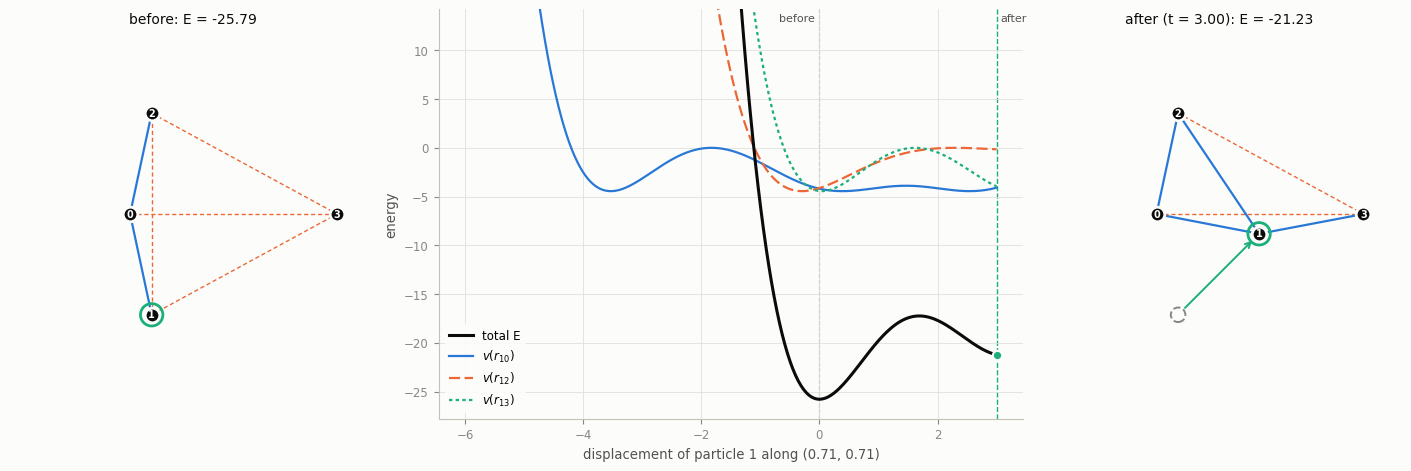

In [152]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), layout="constrained", gridspec_kw={"width_ratios": [1, 1.6, 1]})
_ = plot_move(DW_energy, samples[names[0]], k=1, vec=(1, 1), t_range=(-6, 3), axes=axes)

In [155]:
_BLUES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
ENERGY_CMAP = LinearSegmentedColormap.from_list("dw4_energy", _BLUES[::-1])
def _contour(ax, U, V, E, clip, label):
    vmin = E.min()
    vmax = min(E.max(), vmin + clip)
    levels = np.linspace(vmin, vmax, 25)
    cs = ax.contourf(U, V, np.minimum(E, vmax), levels=levels, cmap=ENERGY_CMAP)
    ax.contour(U, V, E, levels=levels[::3], colors="white", linewidths=0.4, alpha=0.6)
    cb = plt.colorbar(cs, ax=ax, shrink=0.85, pad=0.02)
    cb.set_label(f"{label} (clipped at min + {clip:g})", color=INK2, fontsize=8.5)
    cb.outline.set_visible(False)
    cb.locator = MaxNLocator(6)
    cb.update_ticks()
    cb.ax.tick_params(labelsize=8, colors=MUTED)
    ax.grid(False)
    return cs

def slice_2d(energy_fn, x0, dir1, dir2, us, vs):
    "E(x0 + u * dir1 + v * dir2) "
    x0, d1, d2 = np.ravel(x0), np.ravel(dir1), np.ravel(dir2)
    U, V = np.meshgrid(us, vs)
    X = torch.tensor(x0[None] + U.ravel()[:, None] * d1[None] + V.ravel()[:, None] * d2[None]).view(-1, 4, 2)
    with torch.no_grad():
        E = energy_fn(X)
    return E.detach().cpu().numpy().reshape(U.shape)

def particle_direction(k, vec):
    """Direction in R^8 that moves only particle k along the 2D vector `vec`."""
    d = np.zeros((4, 2))
    d[k] = vec
    return d.ravel()

def plot_particle_contour(energy_fn, x0, k, extent=8.0, n=250, clip=30.0, show_wells=True, ax=None, title=None, legend=True):
    """Move particle k over the plane while the other three stay fixed; contour E.
    Dashed circles: radii R_SHORT and R_LONG around each fixed particle, i.e. where the
    pair term with that particle is at a minimum."""
    ax = ax or plt.gca()
    p = np.asarray(x0, dtype=float).reshape(4, 2)
    c = p.mean(0)
    us = np.linspace(c[0] - extent, c[0] + extent, n)
    vs = np.linspace(c[1] - extent, c[1] + extent, n)
    # slice_2d moves particle k by (u, v) relative to its start; shift so axes are absolute
    E = slice_2d(energy_fn, x0, particle_direction(k, (1, 0)), particle_direction(k, (0, 1)),
                 us - p[k, 0], vs - p[k, 1])
    U, V = np.meshgrid(us, vs)
    _contour(ax, U, V, E, clip, "energy")
    others = [j for j in range(4) if j != k]
    if show_wells:
        for j in others:
            for rad in (R_SHORT, R_LONG):
                ax.add_patch(Circle(p[j], rad, fill=False, ec="white", lw=0.8, ls=(0, (2, 2)),
                                    alpha=0.85))
    ax.scatter(*p[others].T, s=90, color=SERIES[1], edgecolor="white", linewidth=1.5, zorder=4)
    for j in others:
        ax.annotate(str(j), p[j], ha="center", va="center", fontsize=7, color="white",
                    fontweight="bold", zorder=5)
    halo = [pe.withStroke(linewidth=3.5, foreground=INK)]   # readable on light and dark fills
    ax.scatter(*p[k], s=90, facecolor="none", edgecolor="white", linewidth=1.8, zorder=4,
               path_effects=halo)
    ax.annotate(f"{k} (start)", p[k], xytext=(8, 8), textcoords="offset points", fontsize=8,
                color="white", zorder=5, path_effects=halo)
    imin = np.unravel_index(E.argmin(), E.shape)
    ax.scatter([U[imin]], [V[imin]], marker="x", s=55, color="white", linewidth=1.8, zorder=4,
               path_effects=halo)
    ax.set(xlim=(us[0], us[-1]), ylim=(vs[0], vs[-1]), aspect="equal",
           xlabel=f"x of particle {k}", ylabel=f"y of particle {k}",
           title=title or f"Move particle {k}, others fixed")
    if legend:
        handles = [
            Line2D([], [], ls="", marker="o", ms=8, mfc=SERIES[1], mec="white", label="fixed particle"),
            Line2D([], [], ls="", marker="o", ms=8, mfc="none", mec=INK, mew=1.8,
                   label=f"start of particle {k}"),
            Line2D([], [], ls="", marker="x", ms=7, mec=INK, mew=1.8, label="lowest point in slice"),
        ]
        if show_wells:
            handles.append(Line2D([], [], color=MUTED, ls=(0, (2, 2)), lw=1,
                                  label=f"r = {R_SHORT:.2f} / {R_LONG:.2f} from a fixed particle"))
        ax.legend(handles=handles, loc="lower left", fontsize=7.5, frameon=True,
                  facecolor=SURFACE, edgecolor=GRID, framealpha=0.92)
    return ax

torch.Size([62500, 4, 2])


<Axes: title={'center': 'Move particle 3, others fixed'}, xlabel='x of particle 3', ylabel='y of particle 3'>

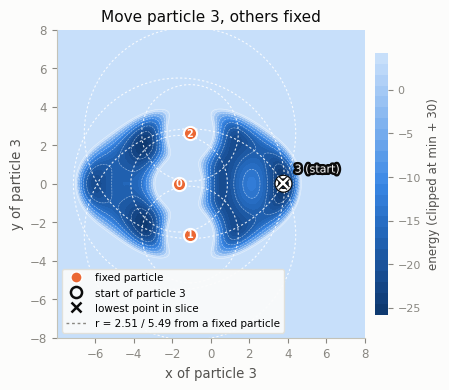

In [156]:
fig, ax = plt.subplots(figsize=(6.5, 4))
plot_particle_contour(DW_energy, samples[names[0]], k=3, ax=ax)